<a href="https://colab.research.google.com/github/Theresa-Gao-0529/MSSP607/blob/main/PARTICIPATION_ACTIVITY_Week_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Participation Activity Week 7


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_FILE = Path('InternetSales(1).csv')
df = pd.read_csv(DATA_FILE, encoding='cp1252', low_memory=False)
df['OrderDate'] = pd.to_datetime(df['OrderDate'], errors='coerce')
df['SalesAmount'] = pd.to_numeric(df['SalesAmount'], errors='coerce')
df = df.dropna(subset=['OrderDate', 'SalesAmount']).copy()
df['Year'] = df['OrderDate'].dt.year
annual_sales = df.groupby('Year', as_index=False)['SalesAmount'].sum()
annual_sales

,Year,SalesAmount
0,2010,4.342104e+04
1,2011,7.075526e+06
2,2012,5.842485e+06
3,2013,1.635155e+07
4,2014,4.569472e+04


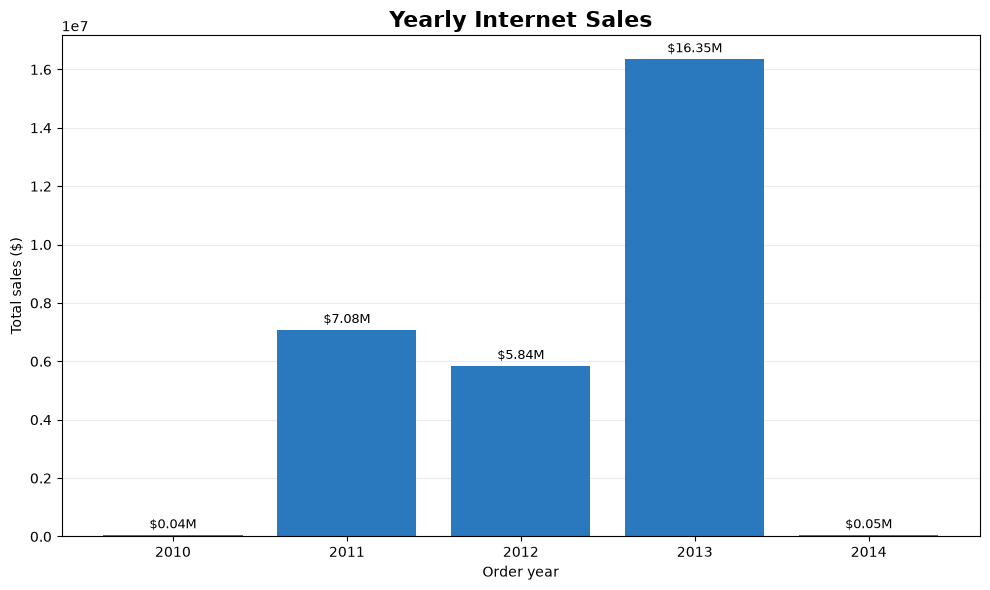

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(annual_sales['Year'].astype(str), annual_sales['SalesAmount'], color='#2A79BE')
ax.set_title('Yearly Internet Sales', fontsize=16, weight='bold')
ax.set_xlabel('Order year')
ax.set_ylabel('Total sales ($)')
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
for bar, value in zip(bars, annual_sales['SalesAmount']):
    ax.annotate(f'${value/1_000_000:.2f}M', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 5), textcoords='offset points', ha='center', fontsize=9)
fig.tight_layout()
fig.savefig('yearly_sales_bar_chart.pdf', format='pdf', bbox_inches='tight')
plt.show()